In [25]:
import json
import random
import re
import time
import unicodedata
from collections import Counter

from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Ustawione ziarno losowosci: {SEED}")
print(f"Urzadzenie: {device}")

ds = load_dataset("Helsinki-NLP/opus-100", "en-pl")
ds

Ustawione ziarno losowosci: 42
Urzadzenie: mps


DatasetDict({
    test: Dataset({
        features: ['translation'],
        num_rows: 2000
    })
    train: Dataset({
        features: ['translation'],
        num_rows: 1000000
    })
    validation: Dataset({
        features: ['translation'],
        num_rows: 2000
    })
})

# Część 1: Przygotowanie danych, słowniki i DataLoader

### 1.1 Normalizacja i tokenizacja

In [2]:
TOKEN_PATTERN = re.compile(r"\d+(?:[.,]\d+)*|[^\W\d_]+(?:'[^\W\d_]+)*|[^\w\s]")


def normalize_text(text):
    text = unicodedata.normalize("NFKC", text).replace("\u2019", "'")
    return text.casefold()


def tokenize(text):
    return TOKEN_PATTERN.findall(normalize_text(text))


example = ds["train"][0]["translation"]
print(example["pl"], "->", tokenize(example["pl"]))
print(example["en"], "->", tokenize(example["en"]))
print(tokenize("Zapłacił 1.250,50 zł za 3 bilety."))
print(tokenize("I don't know, it's 9:30!"))

W budynku są intruzi! -> ['w', 'budynku', 'są', 'intruzi', '!']
Intruders in the building! -> ['intruders', 'in', 'the', 'building', '!']
['zapłacił', '1.250,50', 'zł', 'za', '3', 'bilety', '.']
['i', "don't", 'know', ',', "it's", '9', ':', '30', '!']


### 1.2 Próbka treningowa oraz zbiory walidacyjny i testowy

In [3]:
TRAIN_SAMPLE_SIZE = 100_000
MAX_LEN = 30


def tokenize_split(split):
    pairs = split["translation"]
    return [(tokenize(pair["pl"]), tokenize(pair["en"])) for pair in pairs]


def keep_pair(src_tokens, tgt_tokens):
    return 1 <= len(src_tokens) <= MAX_LEN and 1 <= len(tgt_tokens) <= MAX_LEN


train_sample = ds["train"].shuffle(seed=SEED).select(range(TRAIN_SAMPLE_SIZE))
train_raw = tokenize_split(train_sample)
train_pairs = [pair for pair in train_raw if keep_pair(*pair)]
val_pairs = tokenize_split(ds["validation"])
test_pairs = tokenize_split(ds["test"])

print(f"Probka treningowa (seed={SEED}): {len(train_raw)} par")
print(f"Po filtrze dlugosci 1-{MAX_LEN} tokenow: {len(train_pairs)} par")
print(f"Walidacja: {len(val_pairs)} par, test: {len(test_pairs)} par (bez filtrowania)")

for name, pairs in [("train", train_pairs), ("validation", val_pairs)]:
    src_lens = np.array([len(src) for src, _ in pairs])
    tgt_lens = np.array([len(tgt) for _, tgt in pairs])
    print(
        f"{name:>10}: dlugosc zrodla mediana={np.median(src_lens):.0f}, max={src_lens.max()} | "
        f"dlugosc celu mediana={np.median(tgt_lens):.0f}, max={tgt_lens.max()}"
    )

Probka treningowa (seed=42): 100000 par
Po filtrze dlugosci 1-30 tokenow: 96397 par
Walidacja: 2000 par, test: 2000 par (bez filtrowania)
     train: dlugosc zrodla mediana=6, max=30 | dlugosc celu mediana=7, max=30
validation: dlugosc zrodla mediana=7, max=143 | dlugosc celu mediana=9, max=149


### 1.3 Słowniki źródłowy i docelowy

In [4]:
PAD_TOKEN, UNK_TOKEN, BOS_TOKEN, EOS_TOKEN = "<pad>", "<unk>", "<bos>", "<eos>"
SRC_SPECIALS = [PAD_TOKEN, UNK_TOKEN]
TGT_SPECIALS = [PAD_TOKEN, UNK_TOKEN, BOS_TOKEN, EOS_TOKEN]
MIN_FREQ = 3
MAX_VOCAB_SIZE = 20_000


class Vocabulary:
    def __init__(self, token_lists, specials, min_freq, max_size):
        counts = Counter(token for tokens in token_lists for token in tokens)
        frequent = [(token, count) for token, count in counts.items() if count >= min_freq]
        frequent.sort(key=lambda item: (-item[1], item[0]))
        self.itos = specials + [token for token, _ in frequent[: max_size - len(specials)]]
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}
        self.unk_idx = self.stoi[UNK_TOKEN]

    def __len__(self):
        return len(self.itos)

    def encode(self, tokens):
        return [self.stoi.get(token, self.unk_idx) for token in tokens]

    def decode(self, ids):
        return [self.itos[idx] for idx in ids]


src_vocab = Vocabulary([src for src, _ in train_pairs], SRC_SPECIALS, MIN_FREQ, MAX_VOCAB_SIZE)
tgt_vocab = Vocabulary([tgt for _, tgt in train_pairs], TGT_SPECIALS, MIN_FREQ, MAX_VOCAB_SIZE)

PAD_IDX = src_vocab.stoi[PAD_TOKEN]
assert PAD_IDX == tgt_vocab.stoi[PAD_TOKEN] == 0
UNK_IDX = tgt_vocab.stoi[UNK_TOKEN]
BOS_IDX = tgt_vocab.stoi[BOS_TOKEN]
EOS_IDX = tgt_vocab.stoi[EOS_TOKEN]


def unk_rate(token_lists, vocab):
    ids = [idx for tokens in token_lists for idx in vocab.encode(tokens)]
    return sum(idx == vocab.unk_idx for idx in ids) / len(ids)


print(f"Slownik zrodlowy (pl): {len(src_vocab)} tokenow, specjalne: {src_vocab.itos[:2]}")
print(f"Slownik docelowy (en): {len(tgt_vocab)} tokenow, specjalne: {tgt_vocab.itos[:4]}")
print("Najczestsze tokeny pl:", src_vocab.itos[2:12])
print("Najczestsze tokeny en:", tgt_vocab.itos[4:14])
print(f"Udzial <unk> w walidacji: pl={unk_rate([s for s, _ in val_pairs], src_vocab):.2%}, "
      f"en={unk_rate([t for _, t in val_pairs], tgt_vocab):.2%}")

Slownik zrodlowy (pl): 17851 tokenow, specjalne: ['<pad>', '<unk>']
Slownik docelowy (en): 11554 tokenow, specjalne: ['<pad>', '<unk>', '<bos>', '<eos>']
Najczestsze tokeny pl: ['.', ',', '?', 'nie', '-', 'to', 'w', 'się', 'i', 'na']
Najczestsze tokeny en: ['.', ',', 'the', 'you', '?', 'i', '-', 'to', 'a', 'of']
Udzial <unk> w walidacji: pl=13.11%, en=4.61%


### 1.4 Dataset, collate_fn i DataLoadery

In [5]:
class TranslationDataset(Dataset):
    def __init__(self, pairs, src_vocab, tgt_vocab):
        self.pairs = pairs
        self.src_vocab = src_vocab
        self.tgt_vocab = tgt_vocab

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        src_tokens, tgt_tokens = self.pairs[idx]
        src_ids = self.src_vocab.encode(src_tokens)
        tgt_ids = self.tgt_vocab.encode(tgt_tokens)
        return (
            torch.tensor(src_ids, dtype=torch.long),
            torch.tensor([BOS_IDX] + tgt_ids, dtype=torch.long),
            torch.tensor(tgt_ids + [EOS_IDX], dtype=torch.long),
        )


def collate_fn(batch):
    src_seqs, tgt_in_seqs, tgt_out_seqs = zip(*batch)
    src = pad_sequence(src_seqs, batch_first=True, padding_value=PAD_IDX)
    tgt_in = pad_sequence(tgt_in_seqs, batch_first=True, padding_value=PAD_IDX)
    tgt_out = pad_sequence(tgt_out_seqs, batch_first=True, padding_value=PAD_IDX)
    return {
        "src": src,
        "src_lengths": torch.tensor([len(seq) for seq in src_seqs], dtype=torch.long),
        "src_mask": src != PAD_IDX,
        "tgt_in": tgt_in,
        "tgt_out": tgt_out,
        "tgt_mask": tgt_out != PAD_IDX,
    }


train_dataset = TranslationDataset(train_pairs, src_vocab, tgt_vocab)
val_dataset = TranslationDataset(val_pairs, src_vocab, tgt_vocab)
test_dataset = TranslationDataset(test_pairs, src_vocab, tgt_vocab)

BATCH_SIZE = 64
train_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, generator=train_generator
)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

print(f"Liczba batchy: train={len(train_loader)}, validation={len(val_loader)}, test={len(test_loader)}")

Liczba batchy: train=1507, validation=32, test=32


### 1.5 Przykład pary i batcha

In [6]:
src_ids, tgt_in_ids, tgt_out_ids = val_dataset[3]
src_tokens, tgt_tokens = val_pairs[3]
pair = ds["validation"][3]["translation"]

print("Tekst zrodlowy:", pair["pl"])
print("Tekst docelowy:", pair["en"])
print()
print("Tokeny zrodla:   ", src_tokens)
print("ID zrodla:       ", src_ids.tolist())
print("Tokeny celu:     ", tgt_tokens)
print()
print("Wejscie dekodera:", tgt_vocab.decode(tgt_in_ids.tolist()))
print("ID wejscia:      ", tgt_in_ids.tolist())
print("Cel predykcji:   ", tgt_vocab.decode(tgt_out_ids.tolist()))
print("ID celu:         ", tgt_out_ids.tolist())

Tekst zrodlowy: Wystarczająco dużo sterydów, by zamknąć cię na jakiś czas.
Tekst docelowy: Definitely enough steroids to put you away for a while.

Tokeny zrodla:    ['wystarczająco', 'dużo', 'sterydów', ',', 'by', 'zamknąć', 'cię', 'na', 'jakiś', 'czas', '.']
ID zrodla:        [978, 239, 1, 3, 78, 1382, 42, 11, 265, 130, 2]
Tokeny celu:      ['definitely', 'enough', 'steroids', 'to', 'put', 'you', 'away', 'for', 'a', 'while', '.']

Wejscie dekodera: ['<bos>', 'definitely', 'enough', 'steroids', 'to', 'put', 'you', 'away', 'for', 'a', 'while', '.']
ID wejscia:       [2, 1064, 250, 8916, 11, 192, 7, 205, 22, 12, 387, 4]
Cel predykcji:    ['definitely', 'enough', 'steroids', 'to', 'put', 'you', 'away', 'for', 'a', 'while', '.', '<eos>']
ID celu:          [1064, 250, 8916, 11, 192, 7, 205, 22, 12, 387, 4, 3]


In [7]:
demo_indices = [3, 0]
demo_batch = collate_fn([val_dataset[idx] for idx in demo_indices])

for idx in demo_indices:
    print(f"pl: {ds['validation'][idx]['translation']['pl']}")
    print(f"en: {ds['validation'][idx]['translation']['en']}")
print()
for key, value in demo_batch.items():
    print(f"{key} {tuple(value.shape)}:\n{value.int()}")

real_targets = demo_batch["tgt_mask"].sum().item()
print(f"\nPozycje celu w tensorze: {demo_batch['tgt_out'].numel()}, ocenianych w stracie: {real_targets}")

train_batch = next(iter(train_loader))
print("\nKsztalty batcha treningowego:", {key: tuple(value.shape) for key, value in train_batch.items()})

pl: Wystarczająco dużo sterydów, by zamknąć cię na jakiś czas.
en: Definitely enough steroids to put you away for a while.
pl: Wbij w żyłę w zgięciu łokciowym i opatrz rękę.
en: Jab it into his antecubital vein, and tape his arm down.

src (2, 11):
tensor([[ 978,  239,    1,    3,   78, 1382,   42,   11,  265,  130,    2],
        [   1,    8,    1,    8,    1,    1,   10,    1, 1103,    2,    0]],
       dtype=torch.int32)
src_lengths (2,):
tensor([11, 10], dtype=torch.int32)
src_mask (2, 11):
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0]], dtype=torch.int32)
tgt_in (2, 14):
tensor([[   2, 1064,  250, 8916,   11,  192,    7,  205,   22,   12,  387,    4,
            0,    0],
        [   2,    1,   15,  149,   83,    1,    1,    5,   14, 1643,   83, 1525,
          125,    4]], dtype=torch.int32)
tgt_out (2, 14):
tensor([[1064,  250, 8916,   11,  192,    7,  205,   22,   12,  387,    4,    3,
            0,    0],
        [   1,   15,  149,   83,

# Część 2: Modele seq2seq bez atencji i z atencją

### 2.1 Enkoder, atencja i dekodery

In [8]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hid_dim, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_IDX)
        self.dropout = nn.Dropout(dropout)
        self.gru = nn.GRU(emb_dim, hid_dim, batch_first=True)

    def forward(self, src, src_lengths):
        embedded = self.dropout(self.embedding(src))
        packed = pack_padded_sequence(embedded, src_lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_outputs, final_state = self.gru(packed)
        outputs, _ = pad_packed_sequence(packed_outputs, batch_first=True, total_length=src.size(1))
        return outputs, final_state


class Decoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hid_dim, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_IDX)
        self.dropout = nn.Dropout(dropout)
        self.gru = nn.GRU(emb_dim, hid_dim, batch_first=True)
        self.out = nn.Linear(hid_dim, vocab_size)

    def forward(self, tgt_in, state, encoder_outputs, src_mask):
        embedded = self.dropout(self.embedding(tgt_in))
        decoder_states, state = self.gru(embedded, state)
        logits = self.out(self.dropout(decoder_states))
        return logits, state, None


class DotProductAttention(nn.Module):
    def forward(self, decoder_states, encoder_outputs, src_mask):
        scores = decoder_states @ encoder_outputs.transpose(1, 2)
        scores = scores.masked_fill(~src_mask.unsqueeze(1), float("-inf"))
        weights = torch.softmax(scores, dim=-1)
        context = weights @ encoder_outputs
        return context, weights


class AttentionDecoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hid_dim, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_IDX)
        self.dropout = nn.Dropout(dropout)
        self.gru = nn.GRU(emb_dim, hid_dim, batch_first=True)
        self.attention = DotProductAttention()
        self.combine = nn.Linear(2 * hid_dim, hid_dim)
        self.out = nn.Linear(hid_dim, vocab_size)

    def forward(self, tgt_in, state, encoder_outputs, src_mask):
        embedded = self.dropout(self.embedding(tgt_in))
        decoder_states, state = self.gru(embedded, state)
        context, weights = self.attention(decoder_states, encoder_outputs, src_mask)
        combined = torch.tanh(self.combine(torch.cat([decoder_states, context], dim=-1)))
        logits = self.out(self.dropout(combined))
        return logits, state, weights


class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, src, src_lengths, src_mask, tgt_in):
        encoder_outputs, final_state = self.encoder(src, src_lengths)
        logits, _, weights = self.decoder(tgt_in, final_state, encoder_outputs, src_mask)
        return logits, weights


@torch.no_grad()
def greedy_decode(model, src, src_lengths, src_mask, max_len):
    encoder_outputs, state = model.encoder(src, src_lengths)
    token = torch.full((src.size(0), 1), BOS_IDX, dtype=torch.long, device=src.device)
    finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    generated, attention = [], []
    for _ in range(max_len):
        logits, state, weights = model.decoder(token, state, encoder_outputs, src_mask)
        token = logits.argmax(dim=-1)
        generated.append(token)
        if weights is not None:
            attention.append(weights)
        finished |= token.squeeze(1) == EOS_IDX
        if finished.all():
            break
    generated = torch.cat(generated, dim=1)
    attention = torch.cat(attention, dim=1) if attention else None
    return generated, attention


def strip_after_eos(ids):
    return ids[: ids.index(EOS_IDX)] if EOS_IDX in ids else ids

**Inicjalizacja stanów i kolejność obliczeń**

- Enkoder: jednokierunkowy GRU, stan początkowy $h_0$ to zera. Dzięki `pack_padded_sequence` stan końcowy $h_N$ jest liczony po ostatnim rzeczywistym tokenie, a nie po `<pad>`.
- Oba dekodery zaczynają od $s_0 = h_N$ (enkoder i dekoder mają ten sam rozmiar stanu) i od tokenu `<bos>`.
- Model z atencją w kroku $t$: najpierw $s_t = \operatorname{GRU}(E_\text{tgt}[y_{t-1}], s_{t-1})$, potem score'y $e_{t,i} = s_t^\top h_i$, maskowanie `<pad>` wartością $-\infty$, softmax po pozycjach źródła i kontekst $c_t = \sum_i \alpha_{t,i} h_i$, na końcu $\tilde s_t = \tanh(W_c[s_t; c_t] + b_c)$ i logity $W_\text{out} \tilde s_t + b_\text{out}$.
- Kontekst nie wraca na wejście GRU, więc przy teacher forcing wszystkie $s_t$ liczymy jednym wywołaniem GRU, a atencję dla wszystkich kroków naraz. Wynik jest taki sam jak przy liczeniu krok po kroku (sprawdzone w 2.3).

### 2.2 Inicjalizacja modeli i liczba parametrów

In [9]:
EMB_DIM = 256
HID_DIM = 512
DROPOUT = 0.2


def count_parameters(module):
    return sum(param.numel() for param in module.parameters() if param.requires_grad)


criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

model_no_attention = Seq2Seq(
    Encoder(len(src_vocab), EMB_DIM, HID_DIM, DROPOUT),
    Decoder(len(tgt_vocab), EMB_DIM, HID_DIM, DROPOUT),
).to(device)
print(model_no_attention)
print(f"Liczba parametrow: {count_parameters(model_no_attention):,} "
      f"(enkoder {count_parameters(model_no_attention.encoder):,}, "
      f"dekoder {count_parameters(model_no_attention.decoder):,})")
print()

model_attention = Seq2Seq(
    Encoder(len(src_vocab), EMB_DIM, HID_DIM, DROPOUT),
    AttentionDecoder(len(tgt_vocab), EMB_DIM, HID_DIM, DROPOUT),
).to(device)
print(model_attention)
print(f"Liczba parametrow: {count_parameters(model_attention):,} "
      f"(enkoder {count_parameters(model_attention.encoder):,}, "
      f"dekoder {count_parameters(model_attention.decoder):,})")

Seq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(17851, 256, padding_idx=0)
    (dropout): Dropout(p=0.2, inplace=False)
    (gru): GRU(256, 512, batch_first=True)
  )
  (decoder): Decoder(
    (embedding): Embedding(11554, 256, padding_idx=0)
    (dropout): Dropout(p=0.2, inplace=False)
    (gru): GRU(256, 512, batch_first=True)
    (out): Linear(in_features=512, out_features=11554, bias=True)
  )
)
Liczba parametrow: 15,820,322 (enkoder 5,752,576, dekoder 10,067,746)

Seq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(17851, 256, padding_idx=0)
    (dropout): Dropout(p=0.2, inplace=False)
    (gru): GRU(256, 512, batch_first=True)
  )
  (decoder): AttentionDecoder(
    (embedding): Embedding(11554, 256, padding_idx=0)
    (dropout): Dropout(p=0.2, inplace=False)
    (gru): GRU(256, 512, batch_first=True)
    (attention): DotProductAttention()
    (combine): Linear(in_features=1024, out_features=512, bias=True)
    (out): Linear(in_features=512, out_features=11554, bia

### 2.3 Kontrola pojedynczego kroku, kształtów i wag atencji

In [10]:
demo = {key: value.to(device) for key, value in demo_batch.items()}


def check_model(model):
    model.eval()
    with torch.no_grad():
        encoder_outputs, final_state = model.encoder(demo["src"], demo["src_lengths"])
        logits, weights = model(demo["src"], demo["src_lengths"], demo["src_mask"], demo["tgt_in"])

        last_real = encoder_outputs[torch.arange(demo["src"].size(0)), demo["src_lengths"] - 1]

        state, step_logits = final_state, []
        for t in range(demo["tgt_in"].size(1)):
            step, state, _ = model.decoder(demo["tgt_in"][:, t : t + 1], state, encoder_outputs, demo["src_mask"])
            step_logits.append(step)
        step_logits = torch.cat(step_logits, dim=1)

        loss = criterion(logits.reshape(-1, logits.size(-1)), demo["tgt_out"].reshape(-1))

    print(f"src {tuple(demo['src'].shape)} -> stany enkodera {tuple(encoder_outputs.shape)}, "
          f"stan koncowy {tuple(final_state.shape)}")
    print(f"tgt_in {tuple(demo['tgt_in'].shape)} -> logity {tuple(logits.shape)}")
    print(f"Stan koncowy = stan po ostatnim rzeczywistym tokenie: {torch.allclose(final_state[0], last_real, atol=1e-6)}")
    print(f"Max roznica logitow (caly ciag vs krok po kroku): {(logits - step_logits).abs().max().item():.2e}")
    print(f"Strata przed uczeniem: {loss.item():.3f}, ln|V_tgt| = {np.log(len(tgt_vocab)):.3f}")
    return weights

In [11]:
check_model(model_no_attention)

src (2, 11) -> stany enkodera (2, 11, 512), stan koncowy (1, 2, 512)
tgt_in (2, 14) -> logity (2, 14, 11554)
Stan koncowy = stan po ostatnim rzeczywistym tokenie: True
Max roznica logitow (caly ciag vs krok po kroku): 5.36e-07
Strata przed uczeniem: 9.314, ln|V_tgt| = 9.355


In [12]:
weights = check_model(model_attention)

print(f"Wagi atencji {tuple(weights.shape)}")
print(f"Suma wag po zrodle: min={weights.sum(-1).min().item():.6f}, max={weights.sum(-1).max().item():.6f}")
print(f"Max waga na pozycjach <pad>: {weights.masked_select(~demo['src_mask'].unsqueeze(1)).max().item():.1f}")
print("Wagi dla przykladu B w kroku 1 (ostatnia pozycja to <pad>):")
print(weights[1, 0].cpu().numpy().round(3))

src (2, 11) -> stany enkodera (2, 11, 512), stan koncowy (1, 2, 512)
tgt_in (2, 14) -> logity (2, 14, 11554)
Stan koncowy = stan po ostatnim rzeczywistym tokenie: True
Max roznica logitow (caly ciag vs krok po kroku): 3.28e-07
Strata przed uczeniem: 9.356, ln|V_tgt| = 9.355
Wagi atencji (2, 14, 11)
Suma wag po zrodle: min=1.000000, max=1.000000
Max waga na pozycjach <pad>: 0.0
Wagi dla przykladu B w kroku 1 (ostatnia pozycja to <pad>):
[0.    0.    0.002 0.    0.004 0.025 0.    0.007 0.038 0.923 0.   ]


### 2.4 Dopasowanie do małej próbki

In [13]:
OVERFIT_SIZE = 64
OVERFIT_STEPS = 300

overfit_dataset = TranslationDataset(train_pairs[:OVERFIT_SIZE], src_vocab, tgt_vocab)
overfit_batch = collate_fn([overfit_dataset[idx] for idx in range(OVERFIT_SIZE)])
overfit_batch = {key: value.to(device) for key, value in overfit_batch.items()}
overfit_targets = [strip_after_eos(row.tolist()) for row in overfit_batch["tgt_out"]]


def overfit_check(model):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    model.train()
    history = []
    for step in range(1, OVERFIT_STEPS + 1):
        optimizer.zero_grad()
        logits, _ = model(overfit_batch["src"], overfit_batch["src_lengths"], overfit_batch["src_mask"], overfit_batch["tgt_in"])
        loss = criterion(logits.reshape(-1, logits.size(-1)), overfit_batch["tgt_out"].reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        if step % 50 == 0:
            history.append(f"{step}: {loss.item():.3f}")

    model.eval()
    generated, _ = greedy_decode(
        model, overfit_batch["src"], overfit_batch["src_lengths"], overfit_batch["src_mask"], max_len=MAX_LEN + 1
    )
    predictions = [strip_after_eos(row.tolist()) for row in generated]
    exact = sum(pred == target for pred, target in zip(predictions, overfit_targets))

    print("Strata treningowa (krok: wartosc):", ", ".join(history))
    print(f"Greedy bez teacher forcing - identyczne z referencja: {exact}/{OVERFIT_SIZE}")
    for idx in range(3):
        print(f"  pl:  {' '.join(train_pairs[idx][0])}")
        print(f"  ref: {' '.join(tgt_vocab.decode(overfit_targets[idx]))}")
        print(f"  gen: {' '.join(tgt_vocab.decode(predictions[idx]))}")

In [14]:
torch.manual_seed(SEED)
overfit_model_no_attention = Seq2Seq(
    Encoder(len(src_vocab), EMB_DIM, HID_DIM, DROPOUT),
    Decoder(len(tgt_vocab), EMB_DIM, HID_DIM, DROPOUT),
).to(device)
overfit_check(overfit_model_no_attention)

Strata treningowa (krok: wartosc): 50: 1.124, 100: 0.065, 150: 0.021, 200: 0.012, 250: 0.009, 300: 0.006
Greedy bez teacher forcing - identyczne z referencja: 64/64
  pl:  zapewne tak .
  ref: i'm sure you do .
  gen: i'm sure you do .
  pl:  są w 7 . kręgu piekła .
  ref: they're in the 7 th circle of hell .
  gen: they're in the 7 th circle of hell .
  pl:  przyjemność i zabijanie .
  ref: pleasure . . . in killing you .
  gen: pleasure . . . in killing you .


In [15]:
torch.manual_seed(SEED)
overfit_model_attention = Seq2Seq(
    Encoder(len(src_vocab), EMB_DIM, HID_DIM, DROPOUT),
    AttentionDecoder(len(tgt_vocab), EMB_DIM, HID_DIM, DROPOUT),
).to(device)
overfit_check(overfit_model_attention)

Strata treningowa (krok: wartosc): 50: 1.769, 100: 0.048, 150: 0.013, 200: 0.008, 250: 0.005, 300: 0.004
Greedy bez teacher forcing - identyczne z referencja: 64/64
  pl:  zapewne tak .
  ref: i'm sure you do .
  gen: i'm sure you do .
  pl:  są w 7 . kręgu piekła .
  ref: they're in the 7 th circle of hell .
  gen: they're in the 7 th circle of hell .
  pl:  przyjemność i zabijanie .
  ref: pleasure . . . in killing you .
  gen: pleasure . . . in killing you .


# Część 3: Uczenie z teacher forcing, checkpointy i generowanie greedy

### 3.1 Funkcje uczenia, ewaluacji i generowania

In [18]:
NUM_EPOCHS = 100
LEARNING_RATE = 1e-3
CLIP_NORM = 1.0
NUM_GREEDY_EXAMPLES = 4

sum_criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX, reduction="sum")


def to_device(batch):
    return {key: value.to(device) for key, value in batch.items()}


def train_epoch(model, optimizer):
    model.train()
    total_loss, total_tokens = 0.0, 0
    for batch in train_loader:
        batch = to_device(batch)
        optimizer.zero_grad()
        logits, _ = model(batch["src"], batch["src_lengths"], batch["src_mask"], batch["tgt_in"])
        loss = criterion(logits.reshape(-1, logits.size(-1)), batch["tgt_out"].reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)
        optimizer.step()
        num_tokens = batch["tgt_mask"].sum().item()
        total_loss += loss.item() * num_tokens
        total_tokens += num_tokens
    return total_loss / total_tokens


def evaluate_loss(model, loader):
    model.eval()
    total_loss, total_tokens = 0.0, 0
    with torch.no_grad():
        for batch in loader:
            batch = to_device(batch)
            logits, _ = model(batch["src"], batch["src_lengths"], batch["src_mask"], batch["tgt_in"])
            total_loss += sum_criterion(logits.reshape(-1, logits.size(-1)), batch["tgt_out"].reshape(-1)).item()
            total_tokens += batch["tgt_mask"].sum().item()
    return total_loss / total_tokens


def translate(model, batch):
    model.eval()
    with torch.no_grad():
        max_len = 2 * batch["src_lengths"].max().item() + 10
        generated, _ = greedy_decode(model, batch["src"], batch["src_lengths"], batch["src_mask"], max_len)
    return [" ".join(tgt_vocab.decode(strip_after_eos(row.tolist()))) for row in generated]


def fit(model, checkpoint_path, history_path, use_attention):
    train_generator.manual_seed(SEED)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {"train_loss": [], "val_loss": [], "greedy": []}
    best_val_loss = float("inf")

    for epoch in range(1, NUM_EPOCHS + 1):
        start = time.time()
        train_loss = train_epoch(model, optimizer)
        val_loss = evaluate_loss(model, val_loader)
        translations = translate(model, greedy_batch)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["greedy"].append({"epoch": epoch, "translations": translations})

        saved = val_loss < best_val_loss
        if saved:
            best_val_loss = val_loss
            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "epoch": epoch,
                    "val_loss": val_loss,
                    "config": {"emb_dim": EMB_DIM, "hid_dim": HID_DIM, "dropout": DROPOUT, "use_attention": use_attention},
                },
                checkpoint_path,
            )
        with open(history_path, "w", encoding="utf-8") as file:
            json.dump(history, file, ensure_ascii=False, indent=2)

        print(f"Epoka {epoch:2d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
              f"{time.time() - start:.0f}s{' | zapisano checkpoint' if saved else ''}")
        for translation in translations:
            print(f"    {translation}")
    return history


greedy_indices = random.Random(SEED).sample(range(len(val_pairs)), NUM_GREEDY_EXAMPLES)
greedy_batch = to_device(collate_fn([val_dataset[idx] for idx in greedy_indices]))

print("Staly zestaw przykladow walidacyjnych do generowania greedy:")
for idx in greedy_indices:
    print(f"  pl:  {ds['validation'][idx]['translation']['pl']}")
    print(f"  ref: {ds['validation'][idx]['translation']['en']}")

Staly zestaw przykladow walidacyjnych do generowania greedy:
  pl:  - Myślałem, że to przez "X".
  ref: - I thought it was with an "X""
  pl:  Jako narzędzia?
  ref: Unless you needed a tool.
  pl:  - Czy próbowałeś palić i pić?
  ref: - Have you tried to smoke and then drink?
  pl:  Kolory, farby, kury domowe z butelkami pełnymi chardonnay.
  ref: Colors, paints, desperate housewives with water bottles full of chardonnay.


### 3.2 Uczenie modelu bez atencji

In [19]:
torch.manual_seed(SEED)
model_no_attention = Seq2Seq(
    Encoder(len(src_vocab), EMB_DIM, HID_DIM, DROPOUT),
    Decoder(len(tgt_vocab), EMB_DIM, HID_DIM, DROPOUT),
).to(device)
history_no_attention = fit(
    model_no_attention, "best_no_attention.pt", "history_no_attention.json", use_attention=False
)

Epoka  1 | train loss 4.3005 | val loss 4.0975 | 39s | zapisano checkpoint
    i thought you'd be a good idea .
    did you get it ?
    - i don't know how many times .
    the <unk> of the <unk> <unk> , <unk> , <unk> , <unk> .
Epoka  2 | train loss 3.5992 | val loss 3.9196 | 39s | zapisano checkpoint
    i thought i was thinking .
    did you hear that ?
    - did you take a drink ?
    <unk> , you can get the <unk> of <unk> <unk> .
Epoka  3 | train loss 3.2631 | val loss 3.8723 | 39s | zapisano checkpoint
    i thought i was thinking about it .
    is that the <unk> ?
    - did you know what i say ?
    <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> <unk> .
Epoka  4 | train loss 3.0192 | val loss 3.8778 | 42s
    - i thought i was thinking .
    is that a little <unk> ?
    - did you know what i want ?
    <unk> , the <unk> of the <unk> <unk> , <unk> <unk> .
Epoka  5 | train loss 2.8303 | val loss 3.9004 | 50s
    i thought i was thinking .
    what is it ?
   

### 3.3 Uczenie modelu z atencją

In [20]:
torch.manual_seed(SEED)
model_attention = Seq2Seq(
    Encoder(len(src_vocab), EMB_DIM, HID_DIM, DROPOUT),
    AttentionDecoder(len(tgt_vocab), EMB_DIM, HID_DIM, DROPOUT),
).to(device)
history_attention = fit(
    model_attention, "best_attention.pt", "history_attention.json", use_attention=True
)

Epoka  1 | train loss 4.3479 | val loss 4.1163 | 48s | zapisano checkpoint
    - i thought you'd be a few .
    <unk> , is it ?
    - did you see the other ?
    <unk> , <unk> , <unk> , <unk> , <unk> .
Epoka  2 | train loss 3.6407 | val loss 3.9391 | 47s | zapisano checkpoint
    - i thought i was thinking .
    did they lose ?
    - did you see your name ?
    <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> .
Epoka  3 | train loss 3.2999 | val loss 3.9048 | 47s | zapisano checkpoint
    i thought i was thinking of " " i was thinking . "
    as as a woman ?
    - did you see the police ?
    <unk> , you are being able to get a <unk> from the <unk> .
Epoka  4 | train loss 3.0529 | val loss 3.9131 | 47s
    i thought i was going to get some of it .
    as as a <unk> ?
    - do you want to meet me and drink ?
    the golden ingredient , the <unk> are a racial of <unk> .
Epoka  5 | train loss 2.8628 | val loss 3.9385 | 47s
    i thought i was g

In [36]:
with open("history_no_attention.json", encoding="utf-8") as file:
    print("=== history_no_attention.json ===")
    print(json.dumps(json.load(file), ensure_ascii=False, indent=2))

with open("history_attention.json", encoding="utf-8") as file:
    print("=== history_attention.json ===")
    print(json.dumps(json.load(file), ensure_ascii=False, indent=2))

=== history_no_attention.json ===
{
  "train_loss": [
    4.300466861372477,
    3.599191766498961,
    3.2630586200767064,
    3.019154456201053,
    2.8302540934951304,
    2.6836036936473993,
    2.5685481393782745,
    2.479144103978731,
    2.4083105647922856,
    2.3499041852233464,
    2.3003330418255286,
    2.257657899946668,
    2.2206071919803088,
    2.1900799463074807,
    2.160951998760959,
    2.135483126052704,
    2.1139344786390493,
    2.094390657321544,
    2.0727088656219617,
    2.055804734879121,
    2.039673980413393,
    2.022859472760672,
    2.0089982147118324,
    1.99828613629297,
    1.9855898086814168,
    1.974051080768034,
    1.962468941054934,
    1.9519302399485026,
    1.9425072790163045,
    1.9356804001181747,
    1.92395758093776,
    1.91577135341915,
    1.9085444580243787,
    1.9021066744843542,
    1.8933797441177838,
    1.8887739010307514,
    1.8802305817436096,
    1.872682714177526,
    1.8681845986391836,
    1.8636686719703408,
    1.

# Część 4: Wykresy, ewaluacja na zbiorze testowym i porównanie modeli

### 4.1 Wykres przebiegu uczenia

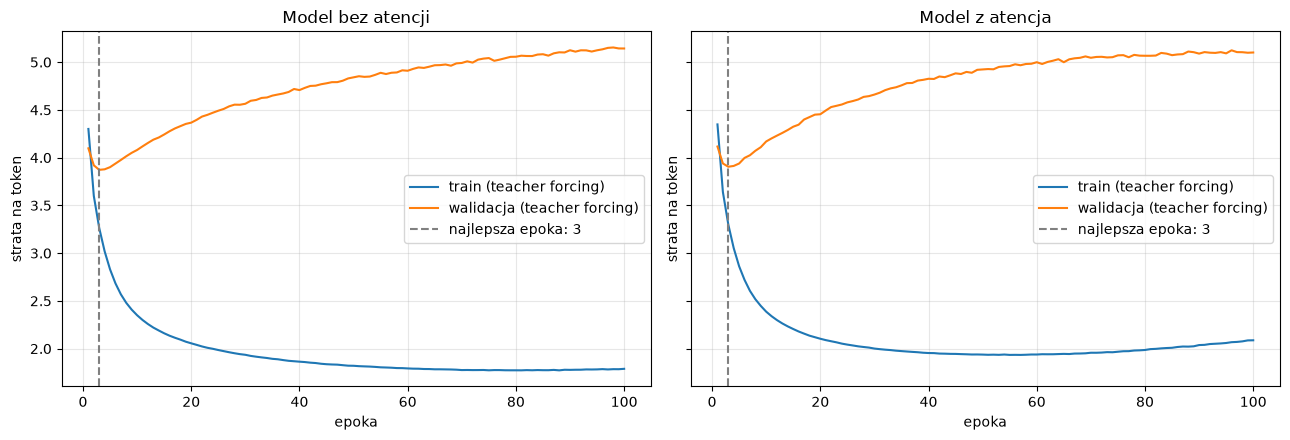

In [21]:
def plot_history(ax, history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    best_epoch = int(np.argmin(history["val_loss"])) + 1
    ax.plot(epochs, history["train_loss"], label="train (teacher forcing)")
    ax.plot(epochs, history["val_loss"], label="walidacja (teacher forcing)")
    ax.axvline(best_epoch, color="gray", linestyle="--", label=f"najlepsza epoka: {best_epoch}")
    ax.set_title(title)
    ax.set_xlabel("epoka")
    ax.set_ylabel("strata na token")
    ax.grid(alpha=0.3)
    ax.legend()


def print_greedy_progress(history):
    best_epoch = int(np.argmin(history["val_loss"])) + 1
    shown_epochs = sorted({1, best_epoch, len(history["greedy"])})
    for idx, source_idx in enumerate(greedy_indices):
        print(f"pl:  {ds['validation'][source_idx]['translation']['pl']}")
        print(f"ref: {ds['validation'][source_idx]['translation']['en']}")
        for epoch in shown_epochs:
            print(f"  epoka {epoch:3d}: {history['greedy'][epoch - 1]['translations'][idx]}")


with open("history_no_attention.json", encoding="utf-8") as file:
    history_no_attention = json.load(file)
with open("history_attention.json", encoding="utf-8") as file:
    history_attention = json.load(file)

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
plot_history(ax_left, history_no_attention, "Model bez atencji")
plot_history(ax_right, history_attention, "Model z atencja")
plt.tight_layout()
plt.show()

In [22]:
print("=== Model bez atencji - tlumaczenia greedy (bez teacher forcing) w wybranych epokach")
print_greedy_progress(history_no_attention)

=== Model bez atencji - tlumaczenia greedy (bez teacher forcing) w wybranych epokach
pl:  - Myślałem, że to przez "X".
ref: - I thought it was with an "X""
  epoka   1: i thought you'd be a good idea .
  epoka   3: i thought i was thinking about it .
  epoka 100: i thought it was the beginning of the <unk> . "
pl:  Jako narzędzia?
ref: Unless you needed a tool.
  epoka   1: did you get it ?
  epoka   3: is that the <unk> ?
  epoka 100: is that your way to the <unk> ?
pl:  - Czy próbowałeś palić i pić?
ref: - Have you tried to smoke and then drink?
  epoka   1: - i don't know how many times .
  epoka   3: - did you know what i say ?
  epoka 100: - do you want to have a drink ?
pl:  Kolory, farby, kury domowe z butelkami pełnymi chardonnay.
ref: Colors, paints, desperate housewives with water bottles full of chardonnay.
  epoka   1: the <unk> of the <unk> <unk> , <unk> , <unk> , <unk> .
  epoka   3: <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> <unk> .
  epoka 100

In [23]:
print("=== Model z atencja - tlumaczenia greedy (bez teacher forcing) w wybranych epokach")
print_greedy_progress(history_attention)

=== Model z atencja - tlumaczenia greedy (bez teacher forcing) w wybranych epokach
pl:  - Myślałem, że to przez "X".
ref: - I thought it was with an "X""
  epoka   1: - i thought you'd be a few .
  epoka   3: i thought i was thinking of " " i was thinking . "
  epoka 100: i thought i had a <unk> .
pl:  Jako narzędzia?
ref: Unless you needed a tool.
  epoka   1: <unk> , is it ?
  epoka   3: as as a woman ?
  epoka 100: as far as ?
pl:  - Czy próbowałeś palić i pić?
ref: - Have you tried to smoke and then drink?
  epoka   1: - did you see the other ?
  epoka   3: - did you see the police ?
  epoka 100: - did you want to stop drinking ?
pl:  Kolory, farby, kury domowe z butelkami pełnymi chardonnay.
ref: Colors, paints, desperate housewives with water bottles full of chardonnay.
  epoka   1: <unk> , <unk> , <unk> , <unk> , <unk> .
  epoka   3: <unk> , you are being able to get a <unk> from the <unk> .
  epoka 100: the <unk> were <unk> in the <unk> , the <unk> <unk> were <unk> .


### 4.2 Wczytanie najlepszych checkpointów i strata testowa

In [26]:
def load_model(checkpoint_path, decoder_class):
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model = Seq2Seq(
        Encoder(len(src_vocab), EMB_DIM, HID_DIM, DROPOUT),
        decoder_class(len(tgt_vocab), EMB_DIM, HID_DIM, DROPOUT),
    ).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    return model, checkpoint


best_no_attention, checkpoint_no_attention = load_model("best_no_attention.pt", Decoder)
best_attention, checkpoint_attention = load_model("best_attention.pt", AttentionDecoder)

test_loss_no_attention = evaluate_loss(best_no_attention, test_loader)
test_loss_attention = evaluate_loss(best_attention, test_loader)

pd.DataFrame(
    {
        "epoka checkpointu": [checkpoint_no_attention["epoch"], checkpoint_attention["epoch"]],
        "parametry": [count_parameters(best_no_attention), count_parameters(best_attention)],
        "val loss": [checkpoint_no_attention["val_loss"], checkpoint_attention["val_loss"]],
        "test loss": [test_loss_no_attention, test_loss_attention],
        "test perplexity": [np.exp(test_loss_no_attention), np.exp(test_loss_attention)],
    },
    index=["bez atencji", "z atencja"],
).round(4)

,epoka checkpointu,parametry,val loss,test loss,test perplexity
bez atencji,3,15820322,3.8723,3.8582,47.3788
z atencja,3,16345122,3.9048,3.8957,49.1902


### 4.3 Tłumaczenia greedy na zbiorze testowym

In [27]:
def translate_loader(model, loader):
    model.eval()
    hypotheses = []
    with torch.no_grad():
        for batch in loader:
            batch = to_device(batch)
            max_len = 2 * batch["src_lengths"].max().item() + 10
            generated, _ = greedy_decode(model, batch["src"], batch["src_lengths"], batch["src_mask"], max_len)
            hypotheses.extend(generated.cpu().tolist())
    return hypotheses


def show_translations(indices):
    for idx in indices:
        pair = ds["test"][idx]["translation"]
        print(f"pl:          {pair['pl']}")
        print(f"ref:         {pair['en']}")
        print(f"bez atencji: {' '.join(tgt_vocab.decode(strip_after_eos(hyp_no_attention[idx])))}")
        print(f"z atencja:   {' '.join(tgt_vocab.decode(strip_after_eos(hyp_attention[idx])))}")
        print()


hyp_no_attention = translate_loader(best_no_attention, test_loader)
hyp_attention = translate_loader(best_attention, test_loader)

show_translations(random.Random(SEED).sample(range(len(test_pairs)), 8))

pl:          ...jak wracałam sama ze szkoły muzycznej i cały czas ostrzegała mnie przez obcym panem, który by mnie częstował.. ..cukierkami, a potem pokazywałby mi swojego siusiaka.
ref:         Well, when I was 8 or 9, my mom was so paranoid when I was walking home, from my piano lesson at night, she would always warn me about dirty old men, giving me candy, and then showing me their penis...
bez atencji: - how you left me , you know , the <unk> <unk> . . .
z atencja:   and . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .

pl:          Jest to błędna myśl! Możliwym jest dla niektórych prawdziwych dziatek Bożych być w taki sposób pokonanymi.
ref:         This is a wrong thought! It is possible for some of the Lord's true children to be t

### 4.4 Porównanie na krótszych i dłuższych wejściach

BLEU liczymy własną implementacją (poniżej): korpusowy BLEU-4 z równymi wagami n-gramów 1-4, karą za zwięzłość i bez wygładzania, na tokenach z naszego tokenizatora (małe litery, interpunkcja jako osobne tokeny), z jedną referencją. `<unk>` w hipotezie nigdy nie pasuje do referencji. Wyniki nie są porównywalne z sacreBLEU.

In [28]:
LENGTH_BINS = [0, 5, 10, 20, 30, np.inf]
LENGTH_LABELS = ["1-5", "6-10", "11-20", "21-30", ">30"]
NUMBER_PATTERN = re.compile(r"\d")


def corpus_bleu(hypotheses, references, max_n=4):
    matches, totals = np.zeros(max_n), np.zeros(max_n)
    hyp_len, ref_len = 0, 0
    for hyp, ref in zip(hypotheses, references):
        hyp_len += len(hyp)
        ref_len += len(ref)
        for n in range(1, max_n + 1):
            hyp_ngrams = Counter(tuple(hyp[i : i + n]) for i in range(len(hyp) - n + 1))
            ref_ngrams = Counter(tuple(ref[i : i + n]) for i in range(len(ref) - n + 1))
            matches[n - 1] += sum((hyp_ngrams & ref_ngrams).values())
            totals[n - 1] += max(len(hyp) - n + 1, 0)
    if hyp_len == 0 or matches.min() == 0:
        return 0.0
    brevity_penalty = min(1.0, np.exp(1 - ref_len / hyp_len))
    return 100 * brevity_penalty * np.exp(np.mean(np.log(matches / totals)))


def repeated_bigrams(tokens):
    return {bigram for bigram, count in Counter(zip(tokens, tokens[1:])).items() if count >= 2}


def sentence_losses(model, loader):
    model.eval()
    loss_sums, token_counts = [], []
    with torch.no_grad():
        for batch in loader:
            batch = to_device(batch)
            logits, _ = model(batch["src"], batch["src_lengths"], batch["src_mask"], batch["tgt_in"])
            losses = nn.functional.cross_entropy(
                logits.transpose(1, 2), batch["tgt_out"], ignore_index=PAD_IDX, reduction="none"
            )
            loss_sums.extend(losses.sum(dim=1).cpu().tolist())
            token_counts.extend(batch["tgt_mask"].sum(dim=1).cpu().tolist())
    return loss_sums, token_counts


def sentence_table(model, hypotheses):
    loss_sums, token_counts = sentence_losses(model, test_loader)
    rows = []
    for hyp_ids, (src_tokens, tgt_tokens), loss_sum, num_tokens in zip(hypotheses, test_pairs, loss_sums, token_counts):
        hyp_tokens = tgt_vocab.decode(strip_after_eos(hyp_ids))
        src_numbers = [token for token in src_tokens if NUMBER_PATTERN.search(token)]
        rows.append(
            {
                "src_len": len(src_tokens),
                "hyp": hyp_tokens,
                "ref": tgt_tokens,
                "loss_sum": loss_sum,
                "num_tokens": num_tokens,
                "length_ratio": len(hyp_tokens) / len(tgt_tokens),
                "eos": EOS_IDX in hyp_ids,
                "repetition": bool(repeated_bigrams(hyp_tokens) - repeated_bigrams(tgt_tokens)),
                "src_numbers": len(src_numbers),
                "kept_numbers": sum(number in hyp_tokens for number in src_numbers),
            }
        )
    table = pd.DataFrame(rows)
    table["dlugosc zrodla"] = pd.cut(table["src_len"], bins=LENGTH_BINS, labels=LENGTH_LABELS)
    return table


def summarize(table):
    def summary(group):
        return pd.Series(
            {
                "liczba par": len(group),
                "test loss (TF)": group["loss_sum"].sum() / group["num_tokens"].sum(),
                "BLEU": corpus_bleu(group["hyp"].tolist(), group["ref"].tolist()),
                "dl. hipotezy / referencji": group["length_ratio"].mean(),
                "zakonczone <eos> [%]": 100 * group["eos"].mean(),
                "powtorzenia [%]": 100 * group["repetition"].mean(),
                "zachowane liczby [%]": 100 * group["kept_numbers"].sum() / max(group["src_numbers"].sum(), 1),
            }
        )

    by_length = table.groupby("dlugosc zrodla", observed=True).apply(summary, include_groups=False)
    by_length.loc["wszystkie"] = summary(table)
    return by_length


table_no_attention = sentence_table(best_no_attention, hyp_no_attention)
table_attention = sentence_table(best_attention, hyp_attention)

comparison = pd.concat(
    {"bez atencji": summarize(table_no_attention), "z atencja": summarize(table_attention)}, axis=0
).round(3)
comparison["liczba par"] = comparison["liczba par"].astype(int)
comparison

liczba par  test loss (TF)   BLEU  \
            dlugosc zrodla                                      
bez atencji 1-5                    650           3.399  5.349   
            6-10                   830           3.467  5.484   
            11-20                  399           4.051  3.533   
            21-30                   82           4.608  1.409   
            >30                     39           5.245  0.000   
            wszystkie             2000           3.858  4.171   
z atencja   1-5                    650           3.437  5.422   
            6-10                   830           3.501  4.469   
            11-20                  399           4.121  3.187   
            21-30                   82           4.634  1.359   
            >30                     39           5.205  1.013   
            wszystkie             2000           3.896  3.577   

                            dl. hipotezy / referencji  zakonczone <eos> [%]  \
            dlugosc zrodla                                                    
bez atencji 1-5                                 0.863               100.000   
            6-10                                1.011                99.518   
            11-20                               1.228                97.995   
            21-30                               1.409                89.024   
            >30                                 1.205                84.615   
            wszystkie                           1.026                98.650   
z atencja   1-5                                 1.001                99.231   
            6-10                                1.095                98.795   
            11-20                               1.261                97.243   
            21-30                               1.485                85.366   
            >30                                 1.245                87.179   
            wszystkie                           1.117                97.850   

                            powtorzenia [%]  zachowane liczby [%]  
            dlugosc zrodla                                         
bez atencji 1-5                       5.538                50.000  
            6-10                     25.422                37.143  
            11-20                    61.905                16.418  
            21-30                    85.366                 4.545  
            >30                      92.308                10.959  
            wszystkie                30.000                18.660  
z atencja   1-5                       7.077                50.000  
            6-10                     24.337                31.429  
            11-20                    59.649                19.403  
            21-30                    87.805                13.636  
            >30                      94.872                23.288  
            wszystkie                29.750                23.923

In [29]:
long_indices = [idx for idx, (src_tokens, _) in enumerate(test_pairs) if len(src_tokens) > 30]
print(f"=== Dlugie wejscia (>30 tokenow): {len(long_indices)} par, przyklady:\n")
show_translations(random.Random(SEED).sample(long_indices, 3))

=== Dlugie wejscia (>30 tokenow): 39 par, przyklady:

pl:          Jeśli dowiem się, że ochraniasz tego zabójcę, to nie tylko cię aresztuję, ale i upewnię się żeby każda gazeta dowiedziała się, że jest ksiądz który myśli, iż psychopaci powinni być egzorcyzmowani zamiast zamykania ich w więzieniach.
ref:         If you're protecting this killer, I will arrest you, and make sure that every newspaper knows there's a priest who thinks psychopaths should be exorcised instead of locked up.
bez atencji: if you don't know , but if you weren't in the <unk> , that is the best of the <unk> that you have to be able to be able to make the <unk> and <unk> , but it is not to be able to be able to be able to be able to make it .
z atencja:   if i don't know , but if you want to find out , we can convince that the <unk> <unk> still <unk> in the <unk> , and the only way that is going to be able to be able to be able to be able to be <unk> .

pl:          Chociaż w swoich zaleceniach z roku 2002 i 2004 M

In [30]:
number_indices = [idx for idx, (src_tokens, _) in enumerate(test_pairs) if any(NUMBER_PATTERN.search(t) for t in src_tokens)]
print(f"=== Wejscia z liczbami: {len(number_indices)} par, przyklady:\n")
show_translations(random.Random(SEED).sample(number_indices, 4))

=== Wejscia z liczbami: 106 par, przyklady:

pl:          Nie żeby go potrzebował, miał już chyba ze 3 samochody.
ref:         Bob just drank beers. We talked and listened to Mark's nonsense theories about everything.
bez atencji: i don't think i should have any more of it , but i think i should have one .
z atencja:   unless he didn't have to be sure he was murdered .

pl:          20 procent od artykułów luksusowych, 50 procent od kobiet i hazardu.
ref:         20 per cent on luxury items, 50 per cent on women and gambling.
bez atencji: 20 minutes , 20 , 20 bucks , 20 bucks , 20 .
z atencja:   20 % of 20 , 20 miles , 20 miles and 20 miles .

pl:          O cokolwiek chodzi, związek cię popiera w 100%.
ref:         Whatever this is about, the Union is behind you 100%.
bez atencji: well , that's what i said , i need to know about the <unk> of the <unk> .
z atencja:   what you want to do with you , you will be able to decide what you want to do with you .

pl:          [5] Informacje po

### 4.5 Mapa atencji

In [31]:
def plot_attention(model, idx):
    batch = to_device(collate_fn([test_dataset[idx]]))
    model.eval()
    with torch.no_grad():
        max_len = 2 * batch["src_lengths"].max().item() + 10
        generated, attention = greedy_decode(model, batch["src"], batch["src_lengths"], batch["src_mask"], max_len)

    out_ids = generated[0].tolist()
    num_steps = len(strip_after_eos(out_ids)) + (EOS_IDX in out_ids)
    weights = attention[0, :num_steps].cpu().numpy()
    src_labels = src_vocab.decode(batch["src"][0].tolist())
    out_labels = tgt_vocab.decode(out_ids[:num_steps])

    fig, ax = plt.subplots(figsize=(0.7 * len(src_labels) + 2, 0.5 * len(out_labels) + 1.5))
    image = ax.imshow(weights, cmap="Blues", vmin=0, vmax=1)
    for row in range(weights.shape[0]):
        for col in range(weights.shape[1]):
            ax.text(col, row, f"{weights[row, col]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if weights[row, col] > 0.5 else "black")
    ax.set_xticks(range(len(src_labels)), src_labels, rotation=45, ha="right")
    ax.set_yticks(range(len(out_labels)), out_labels)
    ax.set_xlabel("tokeny zrodlowe (pl)")
    ax.set_ylabel("wygenerowane tokeny (en)")
    ax.set_title(f"ref: {ds['test'][idx]['translation']['en']}", fontsize=9)
    fig.colorbar(image, ax=ax, fraction=0.03)
    plt.tight_layout()
    plt.show()


attention_candidates = [
    idx
    for idx, (src_tokens, _) in enumerate(test_pairs)
    if 6 <= len(src_tokens) <= 12 and UNK_TOKEN not in src_vocab.decode(src_vocab.encode(src_tokens))
]
attention_example_indices = random.Random(SEED).sample(attention_candidates, 2)

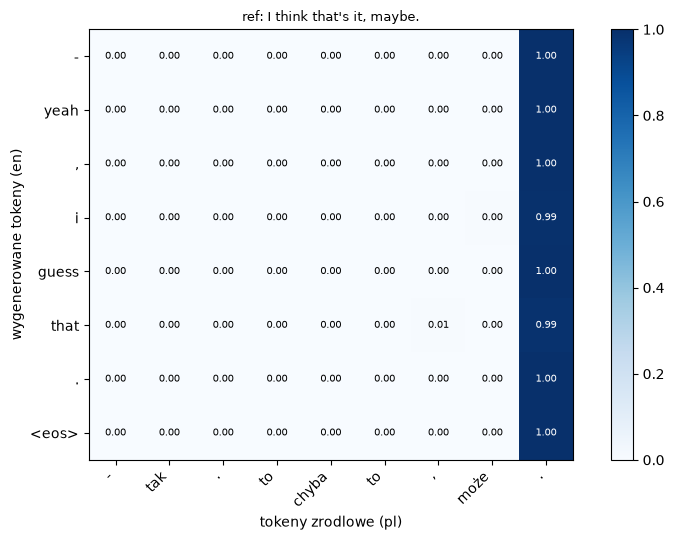

In [32]:
plot_attention(best_attention, attention_example_indices[0])

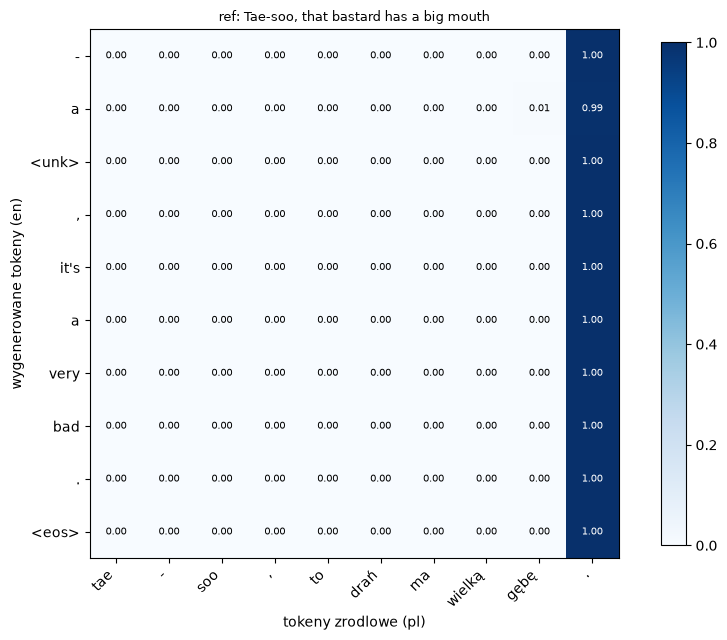

In [33]:
plot_attention(best_attention, attention_example_indices[1])

In [34]:
def attention_on_last_token(model):
    model.eval()
    weights_on_last, last_is_max = [], []
    with torch.no_grad():
        for batch in test_loader:
            batch = to_device(batch)
            _, weights = model(batch["src"], batch["src_lengths"], batch["src_mask"], batch["tgt_in"])
            last_position = (batch["src_lengths"] - 1).view(-1, 1, 1).expand(-1, weights.size(1), 1)
            target_mask = batch["tgt_mask"]
            weights_on_last.extend(weights.gather(2, last_position).squeeze(2)[target_mask].cpu().tolist())
            last_is_max.extend((weights.argmax(dim=-1) == last_position.squeeze(2))[target_mask].cpu().tolist())
    return np.mean(weights_on_last), np.mean(last_is_max)


torch.manual_seed(SEED)
untrained_attention = Seq2Seq(
    Encoder(len(src_vocab), EMB_DIM, HID_DIM, DROPOUT),
    AttentionDecoder(len(tgt_vocab), EMB_DIM, HID_DIM, DROPOUT),
).to(device)

mean_last_trained, max_last_trained = attention_on_last_token(best_attention)
mean_last_untrained, max_last_untrained = attention_on_last_token(untrained_attention)

pd.DataFrame(
    {
        "srednia waga ostatniego tokenu zrodla": [mean_last_trained, mean_last_untrained],
        "kroki z maksimum na ostatnim tokenie [%]": [100 * max_last_trained, 100 * max_last_untrained],
    },
    index=["po uczeniu (checkpoint)", "przed uczeniem"],
).round(3)

,srednia waga ostatniego tokenu zrodla,kroki z maksimum na ostatnim tokenie [%]
po uczeniu (checkpoint),0.917,93.810
przed uczeniem,0.293,36.732


### 4.6 Porównanie modeli i wnioski

- **Przebieg uczenia.** Oba modele osiągają najniższą stratę walidacyjną w 3. epoce. Potem strata treningowa spada, modele szybko się przeuczają.
- **Wynik na teście.** Model bez atencji jest nieznacznie lepszy, a różnice są małe - dodanie atencji nie poprawiło wyniku.
- **Krótsze i dłuższe wejścia.** W obu modelach jakość wyraźnie spada z długością źródła. Model z atencją ma nieco niższą stratę tylko dla wejść >30 tokenów (5.205 wobec 5.245), ale to 39 par, za mało, by uznać to za przewagę.
- **Pominięcia.** Przy długich zdaniach oba modele tłumaczą najwyżej początek, a resztę treści gubią lub zastępują ogólnikami i `<unk>` (przykłady w 4.4).
- **Mapa atencji.** W obu przykładach prawie cała waga (ok. 1.0) w każdym kroku trafia na ostatni token źródła. Na całym teście jest to średnio 0.92 wagi, a w 94% kroków maksimum wypada na ostatniej pozycji (przed uczeniem: 0.29 i 37%). Atencja zdegenerowała się do odczytu $h_N$, który dekoder dostaje już jako $s_0$, więc model z atencją działa w praktyce jak model bez atencji z dodatkową warstwą - stąd brak poprawy.
- **Ograniczenia.** Słownik słów zostawia ok. 13% `<unk>` w polskim źródle, próbka uczenia jest mała i mieszana (napisy filmowe i teksty urzędowe UE), a dekodowanie greedy podejmuje wyłącznie lokalne decyzje.

## Wykorzystanie AI

- Narzędzie: OpenCode (OpenChamber), model: Claude Opus 5.5.
- Zakres: przygotowanie części 1 (wczytanie OPUS-100 en-pl, próbka treningowa, tokenizacja, słowniki, Dataset, collate_fn, DataLoadery, przykłady), części 2 (enkoder GRU, dekoder bez atencji, dekoder z atencją opartą na iloczynie skalarnym, dekodowanie greedy, kontrole implementacji, dopasowanie do małej próbki), części 3 (uczenie z teacher forcing, walidacyjna strata na token, checkpointy, zapis tłumaczeń greedy z każdej epoki) i części 4 (wykresy, ewaluacja checkpointów na teście, BLEU, porównanie według długości wejścia, mapy atencji) oraz omówienie wyboru funkcji dopasowania atencji. Uczenie uruchomił autor.
- Pełna lista promptów znajduje się poniżej.

### Prompty

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
---
name: zajecia-nlp
description: >
  Implements weekly Jupyter tasks for Uczenie głębokie w przetwarzaniu tekstu
  (Christop, AMU) from the live course page, and keeps submissions valid:
  saved notebook outputs, a full prompt log, a Wykorzystanie AI section, and
  ASCII hyphens with straight quotes. Use when editing a course notebook,
  used_prompts.md, a chapter task, tokenization, BoW, BPE, or a submission
  in this repo.
---

# Zajęcia NLP

Task text and dates live on the course page. Fetch them; do not rely on a copied chapter.

https://christop.faculty.wmi.amu.edu.pl/index.php?page=course&id=uczenie-glebokie-w-przetwarzaniu-tekstu

Chapter: `index.php?page=chapter&id=uczenie-glebokie-w-przetwarzaniu-tekstu&topic=<slug>`.

Organizational rules: the same URL with `topic=informacje-organizacyjne`.

Folder `N/` is week N. `N/N.ipynb` is the solution. `N/used_prompts.md` is the prompt log.

## Start

1. Fetch the chapter for this week. Read its **Zadanie** section. Fetch the organizational chapter when a deadline or submission rule is in play.
2. Read `N/N.ipynb` and `N/used_prompts.md`.
3. Restate the requested slice in one short paragraph: inputs, outputs, and the notebook heading it belongs under. Write code after that restatement follows the student's own request. When the message is only a paste of the chapter task, ask them to say what they want done before writing code.

## Implement

4. Change only the requested part. Keep every part of the week's task in the same notebook when the chapter says so.
5. Leave runnable code and saved outputs. Add markdown prose or a comment only where the chapter or the student asks for an explanation, analysis, or comment. Otherwise a section gets its heading alone.
6. Use markdown headings so each part of the task is easy to find.
7. Record the seed when the task asks for an experiment.
8. Fit vocabularies, tokenizers, and model selection on the training and validation splits. Score the chosen checkpoint once on the test split.

## Before you finish

9. Append this turn's user prompt to `N/used_prompts.md`, in send order, including follow-ups. Keep every earlier prompt. Record the tool and model name when they are known.
10. Add or update a notebook section **Wykorzystanie AI**: tool, model name when known, what it did, and a pointer to `used_prompts.md`.
11. In descriptions, conclusions, comments, and README, use the ASCII hyphen `-` and straight quotes `"`. Leave mathematical symbols, characters that belong to the data, and the prompt log as written.
12. Run `python3 .cursor/skills/zajecia-nlp/scripts/check_notebook.py N/N.ipynb`. Fix every reported hit in solution prose, then run it again.
13. Done when the notebook runs from the top, outputs for the requested part are saved, the prompt log includes this turn, **Wykorzystanie AI** points at that log, and the check script exits 0.

## Hand-in

A class task is one `.ipynb` with code, outputs, and the written analysis the chapter asks for.

https://christop.faculty.wmi.amu.edu.pl/index.php?page=chapter&id=uczenie-glebokie-w-przetwarzaniu-tekstu&topic=modele-seq2seq
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
Zakres na tę turę: Część 1: dane, słowniki, DataLoader
Komórka RNN: GRU
Note: wyjasnij czym sie roznia, jakich uzywalismy na zajeciach i co proponujesz
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
yes dot product then
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
ok
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
Also add a README.md to 4/ with libraries setup like in 1/
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
ModuleNotFoundError                       Traceback (most recent call last)
Cell In[1], line 7
      3 import unicodedata
      4 from collections import Counter
      5 
      6 from datasets import load_dataset
----> 7 import matplotlib.pyplot as plt
      8 import numpy as np
      9 import torch
     10 import torch.nn as nn

ModuleNotFoundError: No module named 'matplotlib'
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
Ok. don't add unnecessary comments to each section, only when specifically asked to
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
lets update the skill then to only add it when asked to
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
ok continue with part 2
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
instead of adding a weird loop in 2.2 simply write the code twice for model without attention and with
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
same for others pls
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
you can add helper print functions or smth just dont do those nasty AI slop loops
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
dobra to dawaj teraz teacher forcing oraz zapisuj checkpointy, pamietaj tez o zapisanywaniu greedy bez teacher forcingu
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
dont run the training in the background just create the code and I'll run it myself
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
ok done
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
should be saved now
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
Direction: Keep it and analyse it
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
NameError                                 Traceback (most recent call last)
Cell In[24], line 18
     14 
     15 test_loss_no_attention = evaluate_loss(best_no_attention, test_loader)
     16 test_loss_attention = evaluate_loss(best_attention, test_loader)
     17 
---> 18 pd.DataFrame(
     19     {
     20         "epoka checkpointu": [checkpoint_no_attention["epoch"], checkpoint_attention["epoch"]],
     21         "parametry": [count_parameters(best_no_attention), count_parameters(best_attention)],

NameError: name 'pd' is not defined
```

```text
tool: OpenCode (OpenChamber)
model: Claude Opus 5.5
should attention plot look like this? [image-1.png]
```

```text
tool: OpenCode (OpenChamber)
model: GPT-6 Luna
add prints for history jsons after completing them and add all prompts to 4/ so everything is in one file.
```

```text
tool: OpenCode (OpenChamber)
model: GPT-6 Luna
No. Revert that I meant to add the prompts from assignment 4/ to the 4.ipynb at the end of the file. Also include the prompts from this conversation
```